# Lab 8 Presentation - Tree-based methods and the $F_1$ Score

Lucas Schwengber/Josh Davis

# Learning goals presentation

*(see the [exercise](lab8_exercise.qmd) for the exercise’s goals.)*

1.  Trees, bagging and boosting on a toy problem with a non-linear
    boundary.
2.  Comparing tree-based methods: bias, variance, over/underfitting.
3.  The $F_1$ score.
4.  How to make the $F_1$ non-trivial for unbalanced data.

LLM assistance was used during the elaboration of this presentation and
the exercise.

# Trees, bagging and boosting

## A toy problem with a non-linear boundary

We first consider a non-linear decision boundary which requires some
expressivity to be fit well.

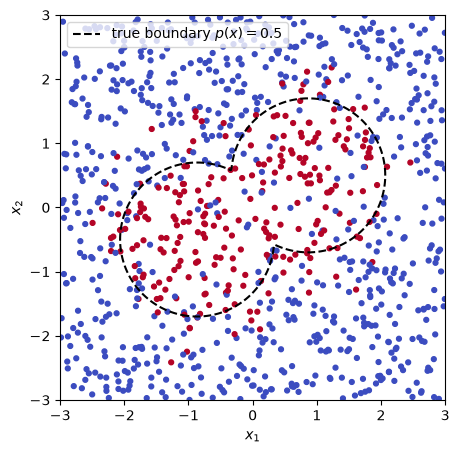

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import expit
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier


class DividingCellWorld:
    """Two features, uniform on a square; p(x) = P(y = 1 | x) is high inside the union of two slightly
    overlapping circles (a cell undergoing division), low outside."""

    def __init__(self, radius=1.2, separation=1.0, angle=np.pi / 6, sharpness=4.0, box=3.0):
        self.radius, self.sharpness, self.box = radius, sharpness, box
        direction = np.array([np.cos(angle), np.sin(angle)])
        self.centers = np.array([-separation * direction, separation * direction])    # 2 * separation apart

    def _scaled_distance(self, X):
        """Distance to the nearest center, divided by the radius; equals 1 on the boundary."""
        dists = np.linalg.norm(X[:, None, :] - self.centers[None, :, :], axis=2)
        return dists.min(axis=1) / self.radius

    def true_prob(self, X):
        return expit(self.sharpness * (1 - self._scaled_distance(X)))

    def simulate(self, n, seed=None):
        rng = np.random.default_rng(seed)
        X = rng.uniform(-self.box, self.box, size=(n, 2))
        y = rng.binomial(1, self.true_prob(X))
        return X, y

    def grid(self, resolution=150):
        """A grid of feature vectors covering the square, for drawing boundaries."""
        g = np.linspace(-self.box, self.box, resolution)
        x0, x1 = np.meshgrid(g, g)
        return x0, x1, np.column_stack([x0.ravel(), x1.ravel()])

    def plot_true_boundary(self, ax, **kwargs):
        x0, x1, G = self.grid()
        kwargs = {"colors": "k", "linestyles": "--", **kwargs}
        ax.contour(x0, x1, self.true_prob(G).reshape(x0.shape), levels=[0.5], **kwargs)


def plot_boundary(model, world, ax, color="C1", label=None, resolution=150, **kwargs):
    """Draw the decision boundary of any fitted classifier (the curve where model.predict changes)."""
    x0, x1, G = world.grid(resolution)
    pred = model.predict(G).reshape(x0.shape)
    ax.contour(x0, x1, pred, levels=[0.5], colors=color, **kwargs)
    if label is not None:
        ax.plot([], [], color=color, label=label)


world = DividingCellWorld()
X_train, y_train = world.simulate(1000, seed=1)
X_test, y_test = world.simulate(5000, seed=2)

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap="coolwarm", s=12)
world.plot_true_boundary(ax)
ax.plot([], [], "k--", label="true boundary $p(x) = 0.5$")
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_aspect("equal"); ax.legend(loc="upper left")
plt.show()

## Comparing tree-based methods

Our goal is to compare how different tree-based methods behave depending
on method type and hyperparameters.

We use the sklearn implementation of three variants of tree-based
methods to compare what their learned decision boundaries look like.

At a high-level, both random forests and gradient boosting are ways of
trying to achieve a favorable bias/variance trade-off when using trees.
However, they do so from opposite ends:

- random forests average expressive trees (which are low bias) to obtain
  a classifier with lower variance.

- gradient boosting combines simple trees (which are low variance) to
  obtain a classifier with lower bias.

The cell below defines a function that returns six tree-based
classifiers: a single decision tree, a random forest and gradient
boosting, each in a “regularized” (less expressive) and an “expressive”
version. For the decision tree, expressivity is controlled by
`min_samples_leaf`, the minimum number of training points each leaf must
contain: a split is only made if both resulting leaves keep at least
that many points, so a larger value gives a coarser, more regularized
tree. For random forests and gradient boosting, we instead vary the
number of trees, `n_estimators`, which plays opposite roles in the two
methods. A random forest averages expressive trees, so a large number of
trees regularizes it: it lowers the variance without making the forest
underfit. Gradient boosting adds up regularized trees, each fitting what
the previous ones missed, so a large number of trees makes it more
expressive.

In [ ]:
def make_methods(seed=0):
    """The six classifiers we compare: three tree-based methods, each in a more regularized (reg) and a more
    expressive (exp) version. What "regularized" means differs by method: a larger min_samples_leaf for the tree,
    more trees for the forest, fewer rounds for boosting."""
    return {
        "decision tree reg": DecisionTreeClassifier(random_state=seed, min_samples_leaf=25),
        "random forest reg": RandomForestClassifier(n_estimators=200, min_samples_leaf=1, random_state=seed),
        "gradient boosting reg": GradientBoostingClassifier(n_estimators=5, random_state=seed, min_samples_leaf=25, learning_rate=1),
        "decision tree exp": DecisionTreeClassifier(random_state=seed, min_samples_leaf=1),
        "random forest exp": RandomForestClassifier(n_estimators=5, min_samples_leaf=1, random_state=seed),
        "gradient boosting exp": GradientBoostingClassifier(n_estimators=200, random_state=seed, min_samples_leaf=25, learning_rate=1),
    }

### Expressivity of the boundary (bias)

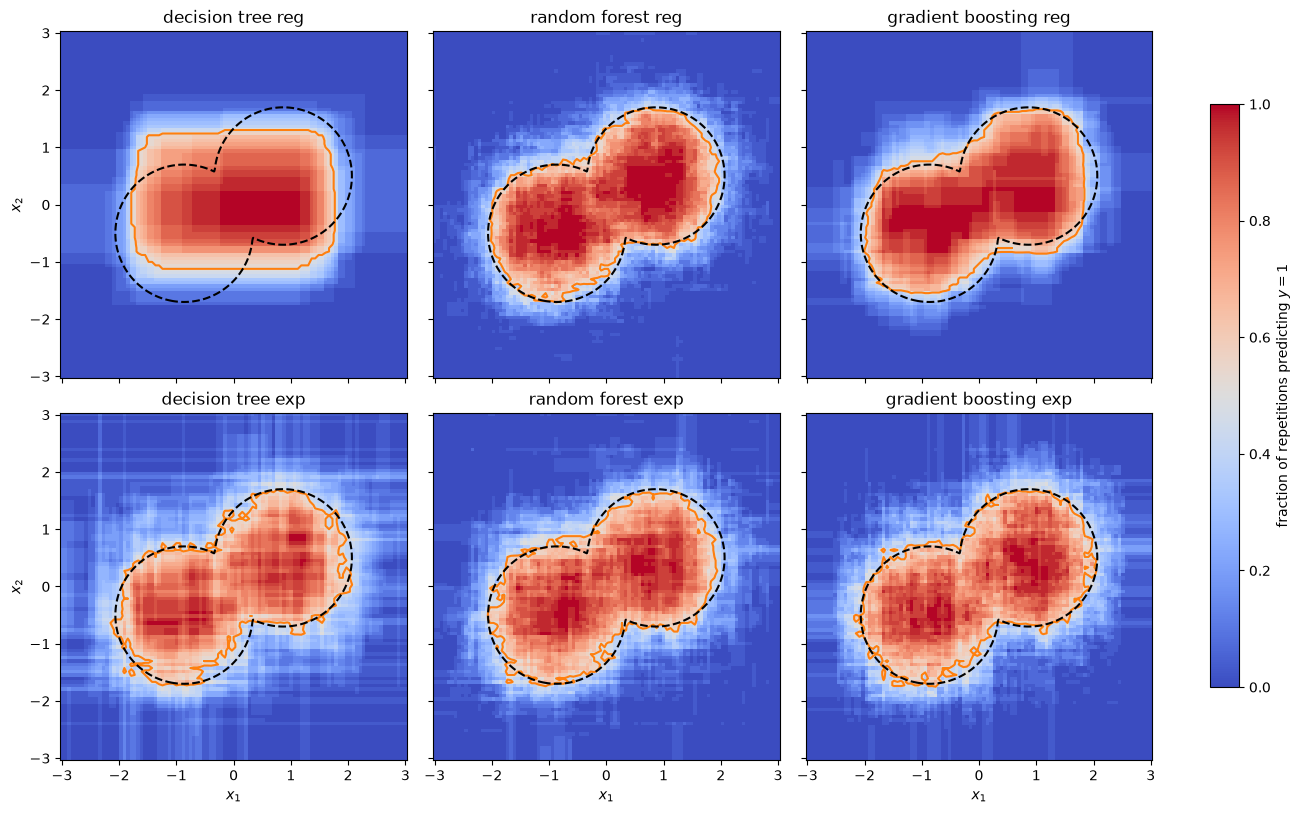

In [3]:
N_REPS, N_TRAIN = 30, 300
x0, x1, G = world.grid(100)

# predictions on the grid, for every repetition and method: shape (n_methods, N_REPS, grid points)
grid_preds = {name: np.empty((N_REPS, len(G)), dtype=int) for name in make_methods()}
fitted = {name: [] for name in make_methods()}    # keep the fitted models for the next plot
for r in range(N_REPS):
    X_r, y_r = world.simulate(N_TRAIN, seed=100 + r)
    for name, model in make_methods(seed=r).items():
        model.fit(X_r, y_r)
        grid_preds[name][r] = model.predict(G)
        fitted[name].append(model)

# 2 x 3 grid: rows are the more regularized (reg) and more expressive (exp) versions, columns the three methods
fig, axes = plt.subplots(2, 3, figsize=(13, 8), sharex=True, sharey=True, constrained_layout=True)
for ax, (name, preds) in zip(axes.ravel(), grid_preds.items()):
    avg = preds.mean(axis=0).reshape(x0.shape)
    im = ax.pcolormesh(x0, x1, avg, cmap="coolwarm", vmin=0, vmax=1, shading="auto")
    ax.contour(x0, x1, avg, levels=[0.5], colors="C1")    # majority-vote boundary: half of the repetitions predict y = 1
    world.plot_true_boundary(ax)
    ax.set_title(name); ax.set_aspect("equal")
for ax in axes[-1]:
    ax.set_xlabel("$x_1$")
for ax in axes[:, 0]:
    ax.set_ylabel("$x_2$")
fig.colorbar(im, ax=axes, label="fraction of repetitions predicting $y = 1$", shrink=0.8)
plt.show()

### Variability of the boundary across repetitions (variance)

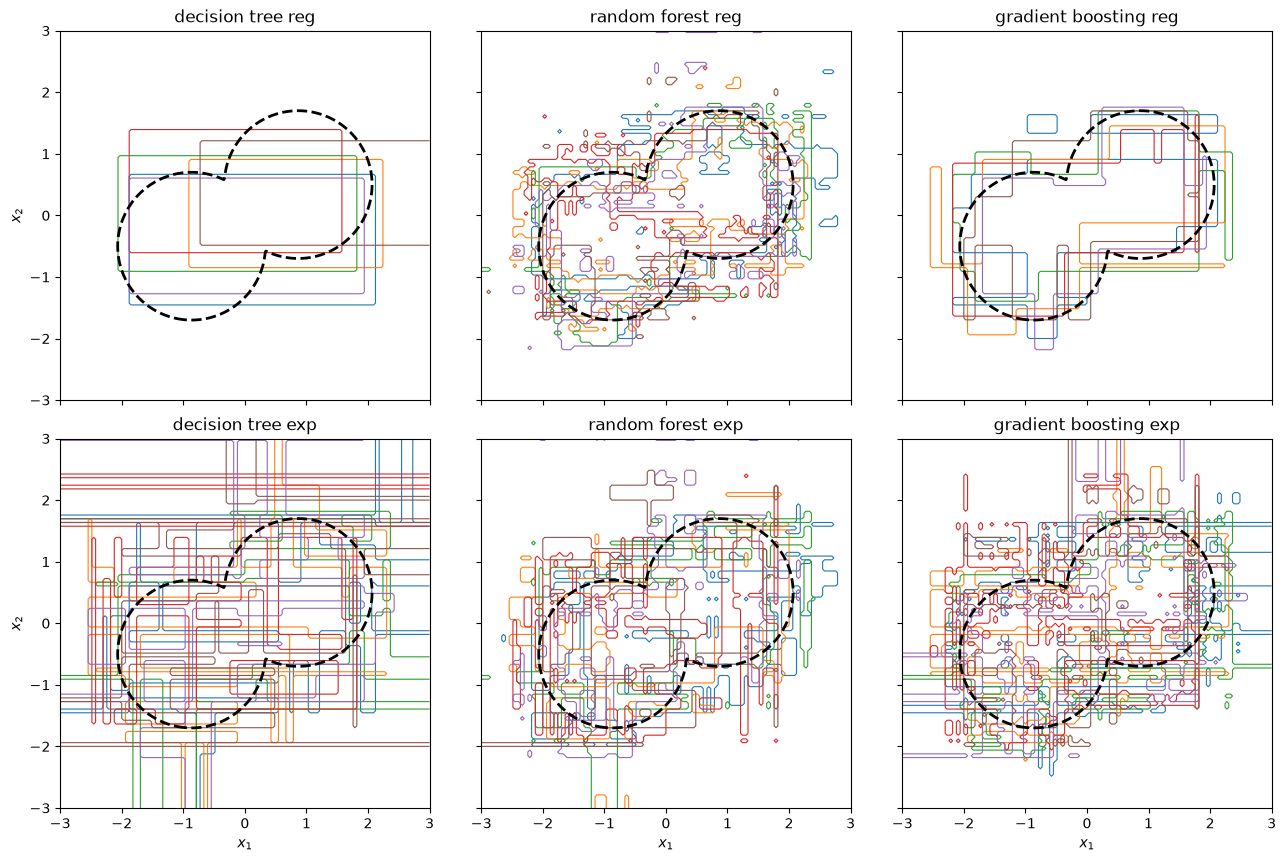

In [4]:
N_SHOW = 6

fig, axes = plt.subplots(2, 3, figsize=(13, 8.5), sharex=True, sharey=True, constrained_layout=True)
for ax, name in zip(axes.ravel(), fitted):
    for r in range(N_SHOW):
        plot_boundary(fitted[name][r], world, ax, color=f"C{r}", resolution=100, linewidths=0.8)
    world.plot_true_boundary(ax, linewidths=2)
    ax.set_title(name); ax.set_aspect("equal")
for ax in axes[-1]:
    ax.set_xlabel("$x_1$")
for ax in axes[:, 0]:
    ax.set_ylabel("$x_2$")
plt.show()

Each colored line is the boundary learned from one training set (6 of
the 30 repetitions), and the dashed line is the true boundary. The more
the colored lines disagree with each other, the higher the variance.

- The **regularized decision tree** has low variance: its boundaries are
  a few large rectangles that move little from one training set to the
  next. But they all miss the shape of the cell, which is the bias we
  saw in the previous plot.
- The **expressive decision tree** is the opposite: its average boundary
  was close to the truth, but the individual boundaries are very
  different from each other, with lines running across the whole square.
- **Random forest:** with 200 trees (top) the boundaries are more
  tightly grouped around the true one than with 5 trees (bottom).
  Averaging more trees lowers the variance.
- **Gradient boosting:** with 200 rounds (bottom) the boundaries are
  much noisier than with 5 rounds (top), with small islands where a
  model has fit the noise in its own training set.

### Bias and variance

This can be more concretly seen in the bias variance decomposition shown
below.

In [5]:
from tqdm import tqdm

N_TREES = [1, 2, 5, 10, 20, 50, 100, 200, 400]
N_REPS_SWEEP = 20
p_grid = world.true_prob(G)


def sweep_forest(X, y, seed):
    """Test and grid predictions of a random forest after each number of trees in N_TREES (trees are added
    incrementally with warm_start)."""
    out = []
    m = RandomForestClassifier(n_estimators=0, warm_start=True, random_state=seed)
    for n in N_TREES:
        m.set_params(n_estimators=n).fit(X, y)
        out.append((m.predict(X_test), m.predict(G)))
    return out


def sweep_boosting(X, y, seed):
    """Same for gradient boosting; staged_predict gives the predictions after each round from a single fit."""
    m = GradientBoostingClassifier(n_estimators=max(N_TREES), random_state=seed).fit(X, y)
    staged = [list(m.staged_predict(Z)) for Z in (X_test, G)]
    return [tuple(s[n - 1] for s in staged) for n in N_TREES]


# results[name] holds test_err of shape (N_REPS_SWEEP, n_settings) and grid predictions of shape
# (N_REPS_SWEEP, n_settings, grid points)
results = {}
for name, sweep in tqdm({"random forest": sweep_forest, "gradient boosting": sweep_boosting}.items()):
    test_err = np.empty((N_REPS_SWEEP, len(N_TREES)))
    gpred = np.empty((N_REPS_SWEEP, len(N_TREES), len(G)), dtype=np.int8)
    for r in range(N_REPS_SWEEP):
        X_r, y_r = world.simulate(N_TRAIN, seed=200 + r)
        for j, (te, g) in enumerate(sweep(X_r, y_r, r)):
            test_err[r, j] = np.mean(te != y_test)
            gpred[r, j] = g
    results[name] = (test_err, gpred)


100%|██████████| 2/2 [00:19<00:00,  9.80s/it]

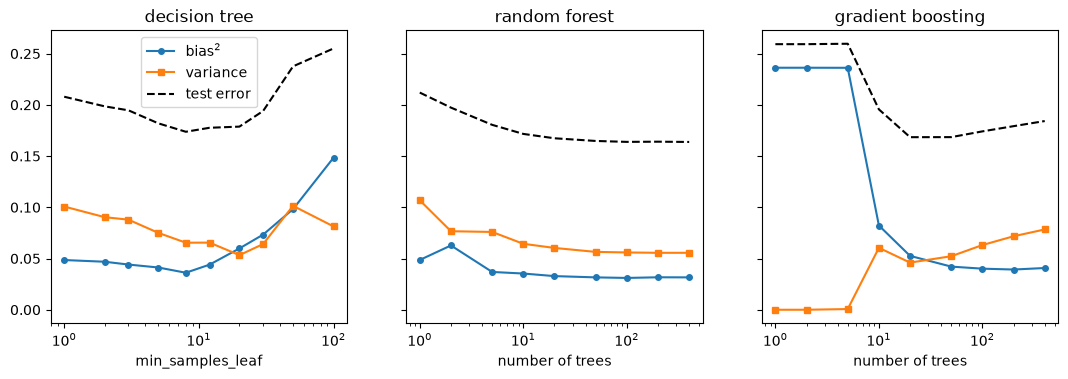

In [6]:
y_star = (p_grid > 0.5).astype(float)
LEAVES = [1, 2, 3, 5, 8, 12, 20, 30, 50, 100]


def bias_variance(gpred):
    """bias^2 and variance of the predicted label over the plane; gpred has shape (reps, settings, grid points)."""
    qbar = gpred.mean(axis=0)
    return ((qbar - y_star) ** 2).mean(axis=1), (qbar * (1 - qbar)).mean(axis=1)


# Fully grown trees (no depth limit), sweeping min_samples_leaf instead
tree_test_err = np.empty((N_REPS_SWEEP, len(LEAVES)))
tree_gpred = np.empty((N_REPS_SWEEP, len(LEAVES), len(G)), dtype=np.int8)
for r in range(N_REPS_SWEEP):
    X_r, y_r = world.simulate(N_TRAIN, seed=200 + r)
    for j, leaf in enumerate(LEAVES):
        m = DecisionTreeClassifier(min_samples_leaf=leaf, random_state=r).fit(X_r, y_r)
        tree_test_err[r, j] = np.mean(m.predict(X_test) != y_test)
        tree_gpred[r, j] = m.predict(G)

# Random forest and gradient boosting against the number of trees, from the sweep above
panels = [("decision tree", LEAVES, "min_samples_leaf", tree_test_err, tree_gpred)]
for name, (test_err, gpred) in results.items():
    panels.append((name, N_TREES, "number of trees", test_err, gpred))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, (name, grid_param, xlabel, test_err, gpred) in zip(axes, panels):
    bias2, variance = bias_variance(gpred)
    ax.plot(grid_param, bias2, "o-", ms=4, label="bias$^2$")
    ax.plot(grid_param, variance, "s-", ms=4, label="variance")
    ax.plot(grid_param, test_err.mean(0), "k--", label="test error")
    ax.set_xscale("log")
    ax.set_title(name); ax.set_xlabel(xlabel)
axes[0].legend()
plt.show()

From this last plot we see that, for forests, variance decreases and
bias stays roughly flat as the number of trees grows: averaging more
trees can only reduce variance, and a forest does not overfit in the
number of trees (Breiman 2001). For boosting the picture is different:
bias keeps decreasing while variance increases with the number of
rounds, so the number of rounds is a genuine complexity parameter that
has to be tuned.

More striking than this trade-off is the discrepancy on how extreme the
behaviours are: random forests are relatively stable with respect to the
number of trees, whereas gradient boosting can change quite
dramatically.

This is overall another asymmetry between them and something one should
take into account: random forests tend to be less sensitive to the
hyperparameter choices, whereas gradient boosting’s performance can
change quite dramatically. This is specially true regarding avoiding
extremes on the bias-variance trade-off. One implication from this is
that random forests tend to be “safer” but can get more quickly
saturated under hyperparameter optimization. Gradient boosting on the
other hand, requires more careful hyperparameter selection, but may pay
off more (Probst et al. 2019). Overall, given a reasonable amount of
observed data points and enough computational resources to do
hyperparameter optimization, gradient boosting tends to perform better.
But random forests do not fare that far below in performance (Grinsztajn
et al. 2022).

# The $F_1$ score

In a classification problem, the simplest metric is **accuracy** (the
fraction of predictions that are correct). As we have seen in the last
lab, however, accuracy can be misleading when classes are imbalanced.
For example for the [exercise’s](lab8_exercise.qmd) dataset, if only 10%
of patients in the dataset are diabetic, a model that predicts “not
diabetic” for everyone achieves 90% accuracy while being completely
trivial (some might say useless). Last time we saw that the confusion
matrix is one way of getting more precise information about performance
of the classifier. However we need to summarize its information by some
means.

The $F_1$ score is another way of addressing this summarization by
focusing specifically on the positive class. It combines two measures of
accuracy for the positive class:

- **Precision** answers: *of all the patients I flagged as diabetic, how
  many actually were?* A model with low precision produces many false
  alarms.
- **Recall** answers: *of all the patients who are truly diabetic, how
  many did I catch?* A model with low recall misses many true cases.

The $F_1$ tries to control both types of error uniformly well. One
classical example where this may be needed is detecting severe but rare
diseases with expensive treatments. In a case like this, we want both of
these types of errors to be simultaneously small: we want most of the
people we assign the treatment to be people who really need it
(precision), but we also do not want to miss out treating people who do
have it (recall). We may be less concerned with the amount of
individuals which we do correctly claim do not have the disease, as they
have no cost and no risk associated, and also it may be fine to provide
treatment to some individuals without the disease, as long as that does
not represent a large fraction of the people we treat.

The $F_1$ score is computed as:
$$F_1 = \frac{2 \cdot \text{precision} \cdot \text{recall}}{\text{precision} + \text{recall}}.$$

Instead of trying to maximize a weighted average of precision and
recall, it instead optimizes their *harmonic* average. The idea here is
that, more importantly than the trade-off between handling both types of
error, we are interested in making sure neither of them is too small.
Equivalently, we want both to be relatively high at the same time. The
$F_1$-score is a classical way of achieving this balance.

By being a harmonic mean, it penalizes imbalance between precision and
recall more harshly than the arithmetic mean would. For instance,
precision $= 1.0$ and recall $= 0.1$ gives $F_1 = 0.18$, whereas the
arithmetic mean would give $0.55$.

This metric is common in tasks for which detecting the positive event is
the key aspect. It originated in information retrieval, where a search
engine should return the relevant documents (recall) without burying
them in irrelevant ones (precision) (Rijsbergen 1979). Besides medical
applications, other examples include image retrieval (Müller et al.
2001), named entity recognition in text (Tjong Kim Sang and De Meulder
2003), fraud detection (Dal Pozzolo et al. 2015) and image segmentation,
where the Dice coefficient used to compare a predicted region with the
true one is exactly the $F_1$ score (Dice 1945).

## Tuning for the $F_1$ score

Whenever we have class imbalance, it will usually be the case that just
optimizing over the default hyperparameters of the method will not be
enough to make it perform well. This is because by default the model
will treat errors on each class as the same, and hence it will tend to
not devote additional effort toward getting the rare positive class
right, leaving precision, recall or both, significantly small.

Fixing this requires a targeted hyperparameter selection which we
discuss now.

Consider a training sample from the same simulation as before, but with
the inside-the-circles class made about ten times rarer (the odds of
$y = 1$ are divided by 10 at every $\boldsymbol{x}$), with the true
boundary $p(\boldsymbol{x}) = 0.5$. Note that the boundary shrinks: at
the former boundary $p(\boldsymbol{x})$ is now only about $0.09$.

fraction of y = 1: train 0.077, validation 0.090, test 0.088

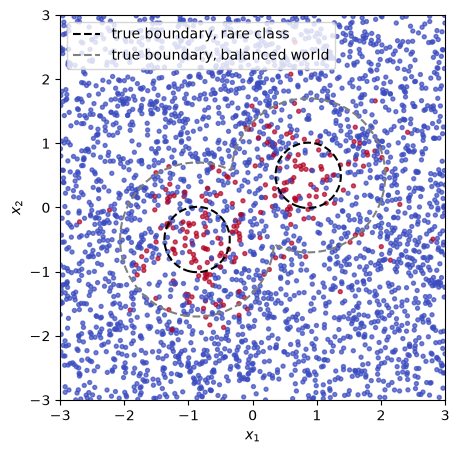

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.metrics import f1_score, precision_score, recall_score


class RareCellWorld(DividingCellWorld):
    """Same geometry, but the odds of y = 1 are multiplied by `positive_odds_factor` everywhere."""

    def __init__(self, positive_odds_factor=0.1, **kwargs):
        super().__init__(**kwargs)
        self.log_factor = np.log(positive_odds_factor)

    def true_prob(self, X):
        return expit(self.sharpness * (1 - self._scaled_distance(X)) + self.log_factor)


rare = RareCellWorld(positive_odds_factor=0.1)
Xr_train, yr_train = rare.simulate(3000, seed=10)
Xr_val, yr_val = rare.simulate(3000, seed=11)        # hold-out set used for hyperparameter selection
Xr_test, yr_test = rare.simulate(20_000, seed=12)
print(f"fraction of y = 1: train {yr_train.mean():.3f}, validation {yr_val.mean():.3f}, test {yr_test.mean():.3f}")

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(Xr_train[:, 0], Xr_train[:, 1], c=yr_train, cmap="coolwarm", s=8, alpha=0.7)
rare.plot_true_boundary(ax)
world.plot_true_boundary(ax, colors="gray")
ax.plot([], [], "k--", label="true boundary, rare class")
ax.plot([], [], color="gray", ls="--", label="true boundary, balanced world")
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_aspect("equal"); ax.legend(loc="upper left")
plt.show()

We consider below two standard hyperparameters which can be selected to
make the $F_1$ non-trivial:

- **Left:** fit once with threshold $0.5$ and unweighted classes, then
  sweep the threshold $t$ on the hold-out probabilities and pick the one
  with the highest hold-out $F_1$.

- **Right:** keep the threshold at $0.5$, but refit the model for each
  class weight $w$ on the positive class (`class_weight={0: 1, 1: w}`)
  and pick the $w$ with the highest hold-out $F_1$.

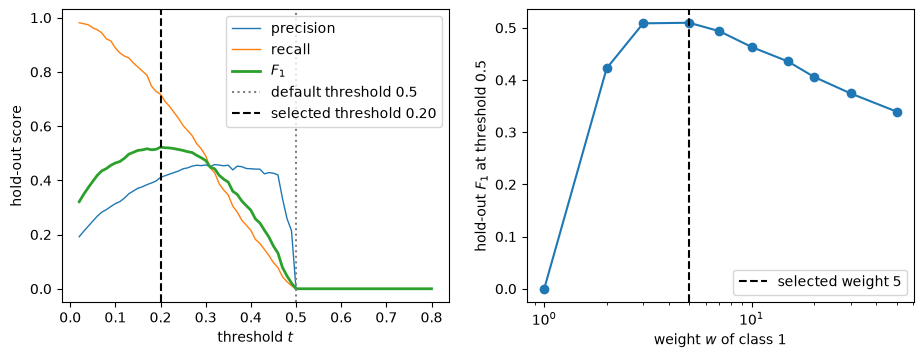

                                     precision   recall   F1
base model, threshold 0.5                0.000    0.000  0.000
tuned threshold 0.20                     0.388    0.695  0.498
class weight 5, threshold 0.5            0.368    0.753  0.495

In [8]:
def base_model(class_weight=None):
    return make_pipeline(PolynomialFeatures(degree=3), StandardScaler(),
                         LogisticRegression(C=1.0, class_weight=class_weight, max_iter=5000))


def scores(y, pred):
    return precision_score(y, pred, zero_division=0), recall_score(y, pred), f1_score(y, pred)


# Base model: default threshold, no class weights
base = base_model().fit(Xr_train, yr_train)
q_val = base.predict_proba(Xr_val)[:, 1]

# (1) threshold selection on the hold-out F1
thresholds = np.linspace(0.02, 0.8, 79)
val_scores = np.array([scores(yr_val, q_val > t) for t in thresholds])
best_t = thresholds[np.argmax(val_scores[:, 2])]

# (2) class weight selection on the hold-out F1, threshold fixed at 0.5
weights = [1, 2, 3, 5, 7, 10, 15, 20, 30, 50]
weighted_models = {w: base_model(class_weight={0: 1, 1: w}).fit(Xr_train, yr_train) for w in weights}
val_f1_w = [f1_score(yr_val, weighted_models[w].predict(Xr_val)) for w in weights]
best_w = weights[int(np.argmax(val_f1_w))]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for j, label in enumerate(["precision", "recall", "$F_1$"]):
    axes[0].plot(thresholds, val_scores[:, j], label=label, lw=2 if j == 2 else 1)
axes[0].axvline(0.5, color="gray", ls=":", label="default threshold 0.5")
axes[0].axvline(best_t, color="k", ls="--", label=f"selected threshold {best_t:.2f}")
axes[0].set_xlabel("threshold $t$"); axes[0].set_ylabel("hold-out score"); axes[0].legend()

axes[1].plot(weights, val_f1_w, "o-")
axes[1].axvline(best_w, color="k", ls="--", label=f"selected weight {best_w}")
axes[1].set_xscale("log"); axes[1].set_xlabel("weight $w$ of class 1"); axes[1].set_ylabel("hold-out $F_1$ at threshold 0.5")
axes[1].legend()
plt.show()

q_test = base.predict_proba(Xr_test)[:, 1]
rows = [("base model, threshold 0.5", q_test > 0.5),
        (f"tuned threshold {best_t:.2f}", q_test > best_t),
        (f"class weight {best_w}, threshold 0.5", weighted_models[best_w].predict(Xr_test) == 1)]
print(f"{'':36s} precision   recall   F1")
for name, pred in rows:
    pr, rc, f1 = scores(yr_test, pred)
    print(f"{name:36s} {pr:9.3f} {rc:8.3f} {f1:6.3f}")

Which one to pick depends on the problem. A key difference is that
thresholding will not significantly change the shape of the decision
boundary, it will only make it fatter or thinner. Whereas re-weighting
may possibly change the shape of the decision boundary (unless the
method is not expressive enough, such as linear ones).

Thresholding has a significant computational advantage since it only
requires fitting the model once, and after it is just several cheap
operations. This makes it more feasible to run on top of other
hyperparameter selections. It however lacks the flexibility of
significantly changing the geometry of the decision boundary as
discussed.

In principle one could use try to optimize both at the same time if the
computational resources are available.

Thresholding is also more principled than it may look: the classifier
with the highest $F_1$ predicts $y = 1$ when $p(\boldsymbol{x})$ is
above some threshold, so a good estimate of $p(\boldsymbol{x})$ combined
with a well-chosen threshold is a sound way to maximize the $F_1$. In
fact, if the estimated probabilities equal $p(\boldsymbol{x})$, the best
threshold is exactly half of the best achievable $F_1$ (Lipton et al.
2014), so it is never above 0.5, and much lower when the positive class
is hard to detect.

Breiman, Leo. 2001. “Random Forests.” *Machine Learning* 45 (1): 5–32.
<https://doi.org/10.1023/A:1010933404324>.

Dal Pozzolo, Andrea, Olivier Caelen, Reid A. Johnson, and Gianluca
Bontempi. 2015. “Calibrating Probability with Undersampling for
Unbalanced Classification.” *2015 IEEE Symposium Series on Computational
Intelligence*, 159–66. <https://doi.org/10.1109/SSCI.2015.33>.

Dice, Lee R. 1945. “Measures of the Amount of Ecologic Association
Between Species.” *Ecology* 26 (3): 297–302.
<https://doi.org/10.2307/1932409>.

Grinsztajn, Léo, Edouard Oyallon, and Gaël Varoquaux. 2022. “Why Do
Tree-Based Models Still Outperform Deep Learning on Typical Tabular
Data?” *Advances in Neural Information Processing Systems 35, Datasets
and Benchmarks Track*.

Lipton, Zachary C., Charles Elkan, and Balakrishnan Narayanaswamy. 2014.
“Optimal Thresholding of Classifiers to Maximize F1 Measure.” *Machine
Learning and Knowledge Discovery in Databases (ECML PKDD 2014)*, Lecture
notes in computer science, vol. 8725: 225–39.
<https://doi.org/10.1007/978-3-662-44851-9_15>.

Müller, Henning, Wolfgang Müller, David McG. Squire, Stéphane
Marchand-Maillet, and Thierry Pun. 2001. “Performance Evaluation in
Content-Based Image Retrieval: Overview and Proposals.” *Pattern
Recognition Letters* 22 (5): 593–601.
<https://doi.org/10.1016/S0167-8655(00)00118-5>.

Probst, Philipp, Anne-Laure Boulesteix, and Bernd Bischl. 2019.
“Tunability: Importance of Hyperparameters of Machine Learning
Algorithms.” *Journal of Machine Learning Research* 20 (53): 1–32.

Rijsbergen, C. J. van. 1979. *Information Retrieval*. 2nd ed.
Butterworths.

Tjong Kim Sang, Erik F., and Fien De Meulder. 2003. “Introduction to the
CoNLL-2003 Shared Task: Language-Independent Named Entity Recognition.”
*Proceedings of the Seventh Conference on Natural Language Learning at
HLT-NAACL 2003*, 142–47.